In [1]:
import tensorflow as tf

In [2]:
tf.config.list_physical_devices("GPU")

[]

In [1]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D
# from tensorflow.keras.layers.advanced_activations import LeakyReLU
import tensorflow as tf
from tensorflow import keras

import tensorflow.keras.layers as layers

model = Sequential()

model.add(layers.Conv2D(filters=96, kernel_size=(11, 11), 
                        strides=(4, 4), activation="relu", 
                        input_shape=(224, 224, 3)))
model.add(layers.BatchNormalization())
model.add(layers.MaxPool2D(pool_size=(3, 3), strides= (2, 2)))

model.add(layers.Conv2D(filters=256, kernel_size=(5, 5), 
                        strides=(1, 1), activation="relu", 
                        padding="same"))
model.add(layers.BatchNormalization())
model.add(layers.MaxPool2D(pool_size=(3, 3), strides=(2, 2)))


model.add(layers.Conv2D(filters=384, kernel_size=(3, 3), 
                        strides=(1, 1), activation="relu", 
                        padding="same"))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(filters=384, kernel_size=(3, 3), 
                        strides=(1, 1), activation="relu", 
                        padding="same"))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(filters=256, kernel_size=(3, 3), 
                        strides=(1, 1), activation="relu", 
                        padding="same"))
model.add(layers.BatchNormalization())

model.add(layers.MaxPool2D(pool_size=(3, 3), strides=(2, 2)))

model.add(layers.Flatten())

model.add(layers.Dense(4096, activation="relu"))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(4096, activation="relu"))
model.add(layers.Dropout(0.5))

#ouput layer
model.add(layers.Dense(1, activation="sigmoid"))


from tensorflow.keras.optimizers import SGD

sgd = SGD(learning_rate=0.01, momentum=0.9)
model.compile(loss = "binary_crossentropy", 
                  optimizer = sgd, 
                  metrics = ["accuracy"])


In [10]:
model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_10 (Conv2D)          (None, 54, 54, 96)        34944     
                                                                 
 batch_normalization_10 (Bat  (None, 54, 54, 96)       384       
 chNormalization)                                                
                                                                 
 max_pooling2d_6 (MaxPooling  (None, 26, 26, 96)       0         
 2D)                                                             
                                                                 
 conv2d_11 (Conv2D)          (None, 26, 26, 256)       614656    
                                                                 
 batch_normalization_11 (Bat  (None, 26, 26, 256)      1024      
 chNormalization)                                                
                                                      

In [11]:
from tensorflow.keras.utils import plot_model

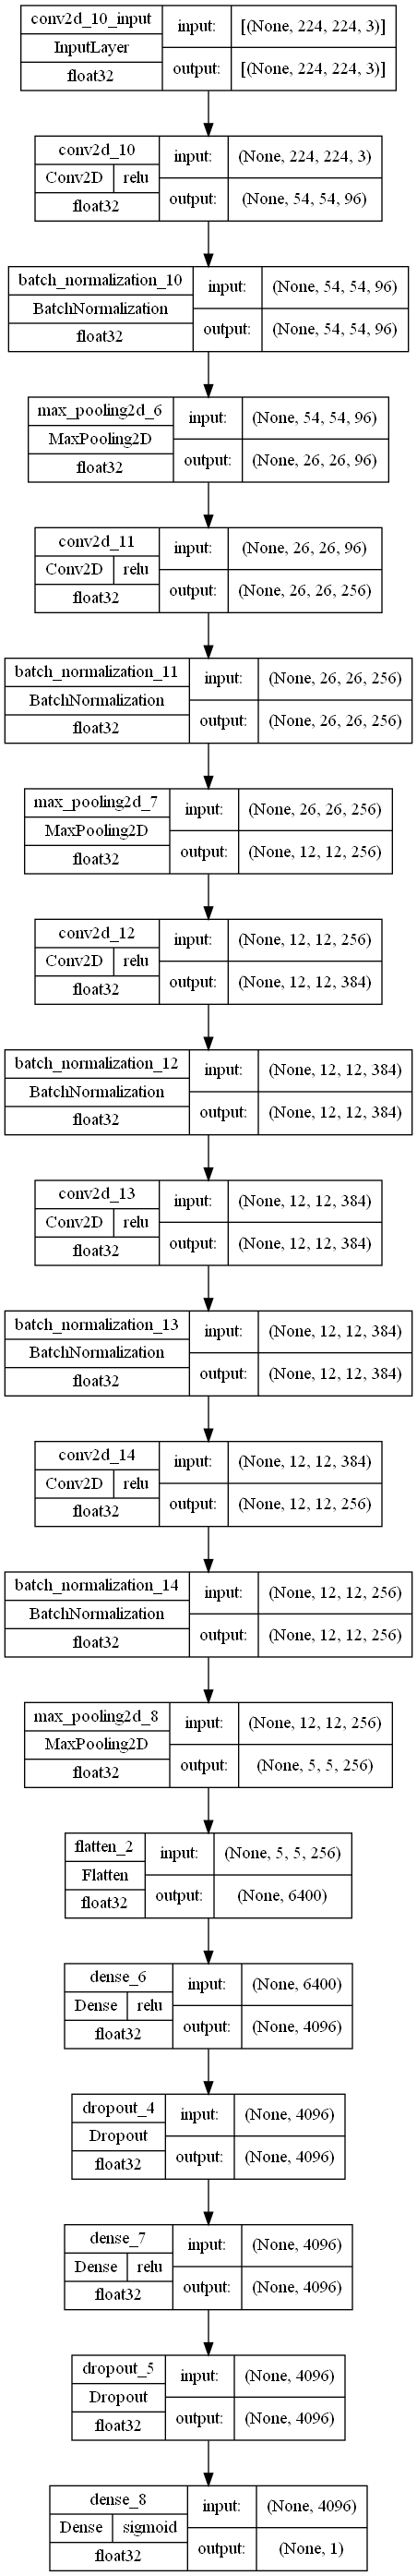

In [12]:
plot_model(model, show_shapes = True, show_dtype = True, show_layer_activations = True)

##### Load the data -- Image Data Generator

In [18]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [19]:
import random

In [65]:
train_data_gen = ImageDataGenerator(rotation_range = random.randint(0,2),#apply rotation randomly from 0 to 5 Degree
                               shear_range = random.randint(0,1)/100,
                               zoom_range = [0,2],
                               horizontal_flip = True,
                               rescale = 1.0/255 )#scaling the pixels

In [66]:
test_data_gen = ImageDataGenerator(rescale = 1.0/255 )

In [67]:
#train data path

train_data = train_data_gen.flow_from_directory(r"E:\dataset\cnn_dataset\training_set",
                                  target_size = (224, 224),
                                  color_mode = "rgb",
                                  class_mode = "binary",
                                  batch_size = 32,
                                  shuffle = True)

Found 8000 images belonging to 2 classes.


In [68]:
train_data

In [69]:
test_data = train_data_gen.flow_from_directory(r"E:\dataset\cnn_dataset\test_set",
                                  target_size = (224, 224),
                                  color_mode = "rgb",
                                  class_mode = "binary",
                                  batch_size = 32,
                                  shuffle = False)

Found 2000 images belonging to 2 classes.


In [70]:
train_data.class_indices

{'cats': 0, 'dogs': 1}

In [71]:
train_data.classes

array([0, 0, 0, ..., 1, 1, 1])

In [72]:
import matplotlib.pyplot as plt

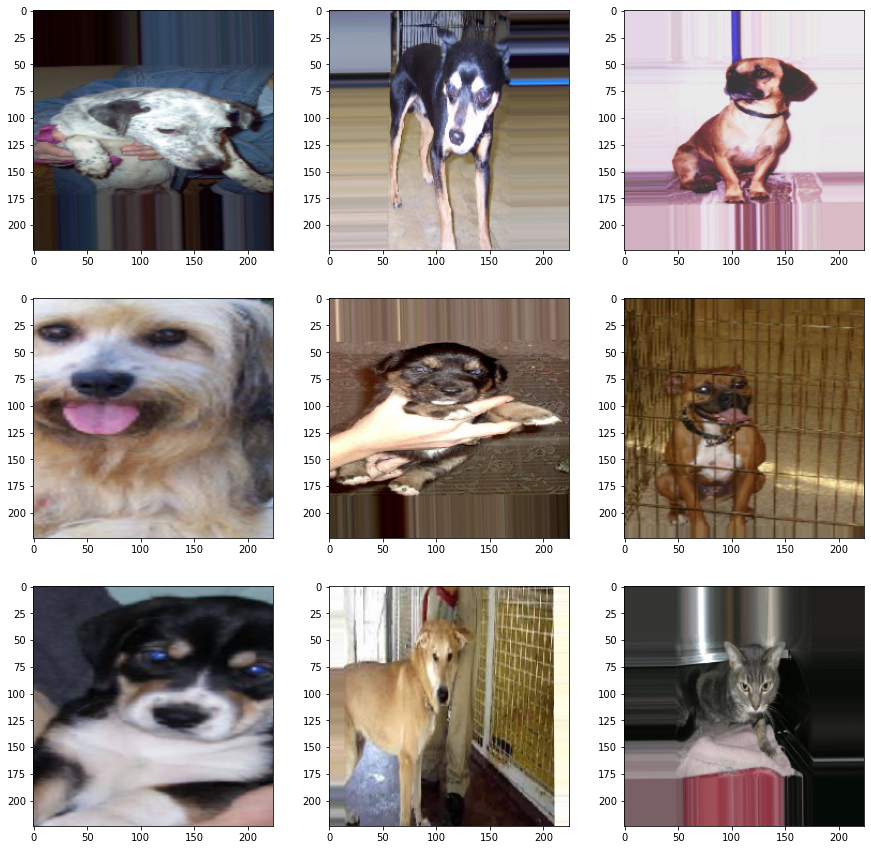

In [73]:
plt.figure(figsize = (15,15))
for idx, each_batch in enumerate(train_data, 1):
#     print(each_batch[0].shape)
#     print(each_batch[1])
    img = each_batch[0][0]
    plt.subplot(3,3,idx)
    plt.imshow(img)
    if idx >= 9:
        break

In [ ]:
#ModelCheckpoint -- class

#filepath -- path to save the best model
#monitor -- which metric should be used to save the best model
#verbose -- printing the status
#mode -- what is mode of the metric -- min or  max
ckpt = ModelCheckpoint("alexnet_cd.weights.h5", monitor = "val_loss",  save_best_only = True,
                       save_weights_only=True, mode = "min")

In [75]:
model.fit(train_data, epochs = 30, callbacks = [ckpt], validation_split=0.1)

Epoch 1/30
 22/250 [=>............................] - ETA: 13:07 - loss: 5.0476 - accuracy: 0.4986

KeyboardInterrupt: 